# A–B–A figures F1–F7, explained

This notebook explains **how every A–B–A figure (F1–F7, `docs/figures/aba_F*.png`) is computed and what it
shows**. It covers the experiment, how task B differs from task A, the learner, every measurement, the
statistics, and then each figure with the code that draws it.

It is **load-only**: it reads the checkpoints copied from the cluster and runs no training at design scale.
Every number printed below is computed here from those checkpoints, and code is shown with
`inspect.getsource`, so the snippets are the code that ran, not a paraphrase.

| run | seeds | grime job | checkpoint (`results/aba/`) | used in |
|---|---|---|---|---|
| original | 0–7 | 4349 | `FULL_2528909f2feaf3f3.jsonl` | F1–F3, F6, F7 |
| replication (confirmatory) | 8–15 | 4396 | `FULL_4e110835b8fc2863.jsonl` | F1–F3, F5–F7 |
| stopping 2×2 (docs/32) | 8–15 | 4538 | `FULL_635c4e3bf8cc6b96[_fixed].jsonl` | F4 |

**Contents.**
1. The experiment: A → B → A
2. How task B differs from A: the label change h and the input change s_f
3. The learner and the richness knob γ₀
4. Measuring A's representation: GLUE capacity and its three channels
5. Behaviour: the network's own accuracy, the refit readout and the bottleneck probe
6. Forward transfer
7. Statistics: intervals, floors, SESOI
8. The figures F1–F7
9. Glossary


In [1]:
import os, sys, math, json, inspect
for _v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ[_v] = "1"
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import aba_lib as L
import aba_summary as S

plt.rcParams.update({"figure.dpi": 70, "font.family": "DejaVu Sans", "figure.facecolor": "#fcfcfb",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb"})

def show(fn):
    """Print the source of a function exactly as it ran."""
    print(inspect.getsource(fn))

def table(header, rows):
    display(Markdown("\n".join(["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
                                + ["| " + " | ".join(str(c) for c in r) + " |" for r in rows])))

DATA = S.load()                         # {"seeds 0–7": {(seed, γ0, h, s_f): row}, "seeds 8–15": {...}}
CELLS32 = S.load_2x2(*S.RUNS_32)        # docs/32: {cell: {(seed, γ0, s_f): row}}
cfg = L.ABAConfig.make(False)
print("arms loaded:", {k: len(v) for k, v in DATA.items()}, "| 2x2 cells:", {k: len(v) for k, v in CELLS32.items()})


arms loaded: {'seeds 0–7': 216, 'seeds 8–15': 216} | 2x2 cells: {'Cr,Cr': 32, 'Fx,Cr': 32, 'Cr,Fx': 32, 'Fx,Fx': 32}


## 1. The experiment: A → B → A

One small network learns three phases in sequence:

```
 init ──train on A──▶ after A ──train on B──▶ after B ──train on A again──▶ after A again
                 (phase A1)            (phase B)                    (phase A2)
```

- **Task A.** P = 16 classes ("manifolds"), each a small cloud of points in d = 150 input dimensions,
  carrying a balanced ±1 label vector y_A: 8 classes +1, 8 classes −1.
- **Task B** reuses the structure but changes the **labels** (by a Hamming distance h) and/or the **inputs**
  (by an input-centre relation s_f). §2 has the details.
- **A2** relearns A. It shows whether what B removed can be recovered (restoration ρ, F1c).
- Every phase is trained **to a fixed fit**: training stops when the training loss reaches ≤ 0.05
  (matched-loss stopping, docs/28 C5). So each learner chooses its own number of updates, its *exposure*,
  and all γ₀ statements hold **at matched current-task fit**. docs/31 and docs/32 (F4) test what changes
  when the number of updates is fixed instead.
- One unit of replication is a **seed**: one draw of A, the labels, B's inputs, the initial weights and the
  probes. Each figure uses 8 seeds per run, and comparisons are **paired** within a seed.

**The grid** (docs/28):
- γ₀ ∈ {0.1, 1, 10}
- h ∈ {0, 4, 8}
- s_f ∈ {1 (frozen), 0.9 (drift), 0.1 (jump)}

That is 27 cells × 8 seeds per run, plus 3 control arms.


In [2]:
print("design config (what changes an arm's result):")
print(json.dumps(cfg.key_fields(), indent=1))
print("grid: γ0", cfg.gammas, "| h", cfg.hammings, "| s_f", cfg.s_fs)


design config (what changes an arm's result):
{
 "P": 16,
 "d": 150,
 "D": 4,
 "R": 1.0,
 "M": 150,
 "N": 300,
 "lr0": 5.0,
 "n_base": 64,
 "target_loss": 0.05,
 "max_steps": 20000,
 "record_every": 25,
 "n_t": 200,
 "center_policy": "all",
 "ntk_per_manifold": 20,
 "probe_hamming": 4,
 "n_probe_neutral": 4,
 "refit_steps": 2000,
 "bottleneck_n": 16
}
grid: γ0 (0.1, 1.0, 10.0) | h (0, 4, 8) | s_f (1.0, 0.9, 0.1)


## 2. How task B differs from A

### 2a. Labels: Hamming distance h

y_B is drawn **at exactly Hamming distance h from y_A** and stays balanced: h/2 of A's +1 classes become −1,
and h/2 of A's −1 classes become +1.
- h = 0: the same labels (a repeat).
- h = 4: a partial change. 4 of 16 labels flip.
- h = 8: an orthogonal change. Half flip, and the label vectors are uncorrelated.

The **label relation** is reported as s_r = 1 − 2·h/P, which gives +1, 0.5 and 0 for h = 0, 4, 8.


In [3]:
show(L.sample_at_hamming)
show(L.s_r)
base = L.seed_base(cfg, 8)                     # seed 8: everything that depends on the seed only
rows = [[h, " ".join("+" if v > 0 else "−" for v in base.y_Bs[h]), int(np.sum(base.y_Bs[h] != base.y_A)),
         f"{L.s_r(base.y_A, base.y_Bs[h]):+.2f}"] for h in cfg.hammings]
table(["h", "y_B (seed 8; y_A is the h = 0 row)", "labels flipped", "s_r(y_A, y_B)"], rows)


def sample_at_hamming(y: np.ndarray, h: int, rng: np.random.Generator) -> np.ndarray:
    """Balanced dichotomy at Hamming distance `h` from `y`: swap h/2 (+1) with h/2 (−1)."""
    out = np.asarray(y, dtype=np.int8).copy()
    P = out.size
    if h < 0 or h > P or h % 2:
        raise ValueError(f"h must be even in [0, P]; got {h}")
    if h == 0:
        return out
    plus, minus = np.flatnonzero(out == 1), np.flatnonzero(out == -1)
    tp = rng.choice(plus, size=h // 2, replace=False)
    tm = rng.choice(minus, size=h // 2, replace=False)
    out[tp], out[tm] = -1, 1
    assert int(np.sum(out != y)) == h and int(out.sum()) == 0
    return out

def s_r(y1: np.ndarray, y2: np.ndarray) -> float:
    """Signed label relation `1 − 2·Hamming/P` (docs/26 A3). −1 for y2 = −y1."""
    y1, y2 = np.asarray(y1), np.asarray(y2)
    return float(1.0 - 2.0 * np.sum(y1 != y2) / y1.size)



| h | y_B (seed 8; y_A is the h = 0 row) | labels flipped | s_r(y_A, y_B) |
|---|---|---|---|
| 0 | − − − − − + + + − + + − + + − + | 0 | +1.00 |
| 4 | − − − − + − − + + + + − + + − + | 4 | +0.50 |
| 8 | + + − + − − − + − + + + + − − − | 8 | +0.00 |

### 2b. Inputs: the centre relation s_f

Each class is a manifold: a **centre** plus D = 4 axes with radius R = 1, sampled at M = 150 training points
and a separate set of test points, plus small noise (ε = 0.01).

B keeps A's axes and point coordinates but **redraws the centres** by an AR(1) step:

c_B = s_f · c_A + √(1 − s_f²) · z,  with z a fresh Gaussian draw, rescaled to the norm of the centres.

| s_f | name | meaning |
|---|---|---|
| 1 | frozen | B uses A's points exactly |
| 0.9 | drift | the centres move a little |
| 0.1 | jump | the centres are nearly new |

The realised input relation ρ_in is the mean cosine between matched A and B centres.


In [4]:
show(L.redraw_centers)
rows = []
for sf in cfg.s_fs:
    B = L.b_arrangement(cfg, base, sf)
    rows.append([sf, S.SF_NAME[sf], f"{np.mean(np.diag(L.centre_cosines(base.A.centers, B.centers))):.3f}",
                 "yes" if B is base.A else "no"])
table(["s_f", "name", "realised ρ_in (seed 8)", "B is A itself"], rows)


def redraw_centers(arr: Arr, rho: float, rng: np.random.Generator) -> Arr:
    """AR(1) centre redraw at `rho`, axes and coords held (`redraw_centers_correlated`).

    `rho = 1` returns `arr` itself — the exact-copy convention for s_f = 1.0.
    """
    if rho >= 1.0:
        return arr
    if rho < 0.0:
        raise ValueError(f"rho must be in [0, 1]; got {rho}")
    P, d = arr.centers.shape
    if rho == 0.0:
        new = _gaussian_rows(rng, P, d)
    else:
        z = _gaussian_rows(rng, P, d)
        prev_rms = float(np.sqrt(np.mean(arr.centers ** 2)))
        z_rms = float(np.sqrt(np.mean(z ** 2)))
        z = z * (prev_rms / z_rms if z_rms > 0 else 1.0)
        new = rho * arr.centers + np.sqrt(1.0 - rho ** 2) * z
    points = _realize_points(new, arr.axes, arr.coords, arr.R, NOISE_EPS, rng)
    test = _realize_points(new, arr.axes, arr.coords, arr.R, NOISE_EPS, rng)
    return Arr(new, arr.axes, arr.coords, points, test, arr.R)



| s_f | name | realised ρ_in (seed 8) | B is A itself |
|---|---|---|---|
| 1.0 | frozen | 1.000 | yes |
| 0.9 | drift | 0.900 | no |
| 0.1 | jump | 0.102 | no |

**The nine configurations together.**

| | frozen (s_f 1) | drift (s_f 0.9) | jump (s_f 0.1) |
|---|---|---|---|
| **h 0** | identical task: the identity control. B starts at criterion and takes 0 updates. | same labels, slightly moved inputs: the benign corner | same labels on new inputs |
| **h 4** | same inputs, 4 labels flipped | | mostly new inputs |
| **h 8** | same inputs, conflicting labels: the worst corner | | new inputs and new labels |


## 3. The learner and the richness knob γ₀

A one-hidden-layer ReLU network, f(x) = s · uᵀ relu(β₀ W x), with N = 300 hidden units and β₀ = d^−½. The
readout u starts at **0**, so f(x) = 0 at init. It is trained by full-batch gradient descent on the mean
squared error, with no weight decay and no normalisation.

**γ₀ sets lazy vs rich training (μP).**
- The output scale is s = N^−½ / (γ₀ √(N/n_base)), and the learning rate is lr = lr0 · γ₀² · N/n_base.
- With **small γ₀ (0.1) the network is "lazy"**. A small change in the readout fits the task, and the hidden
  features W barely move: the network behaves like a fixed-feature (kernel) model.
- With **large γ₀ (10) it is "rich"**. The output is scaled down, so fitting the task requires the
  hidden features themselves to change and align with the task.
- The product lr·s² = lr0/N is the same at every γ₀, so the readout's effective step is matched. Only how
  much the features move differs.


In [5]:
show(L.OneModuleNet.__init__)
show(L.OneModuleNet.hidden)
rows = []
for g in cfg.gammas:
    n = L.OneModuleNet(base.W0, g, cfg)
    rows.append([g, f"{n.s:.2e}", f"{n.lr:.3g}", f"{n.lr * n.s ** 2:.4f}"])
table(["γ0", "output scale s", "learning rate", "lr·s² (= lr0/N)"], rows)


    def __init__(self, W0: np.ndarray, gamma: float, cfg: ABAConfig):
        self.N, self.d = W0.shape
        self.gamma = float(gamma)
        self.W = np.array(W0, dtype=np.float64, copy=True)
        self.u = np.zeros(self.N)
        self.W_init = self.W.copy()
        self.beta0 = self.d ** -0.5
        self.s = self.N ** -0.5 / (gamma * math.sqrt(self.N / cfg.n_base))
        self.lr = cfg.lr0 * gamma ** 2 * (self.N / cfg.n_base)

    def hidden(self, X: np.ndarray) -> np.ndarray:
        return np.maximum(X @ self.W.T * self.beta0, 0.0)



| γ0 | output scale s | learning rate | lr·s² (= lr0/N) |
|---|---|---|---|
| 0.1 | 2.67e-01 | 0.234 | 0.0167 |
| 1.0 | 2.67e-02 | 23.4 | 0.0167 |
| 10.0 | 2.67e-03 | 2.34e+03 | 0.0167 |

**Training to criterion.** The loss is checked before every update, and training stops at loss ≤ 0.05.
Because u(0) = 0, the initial loss is 0.5, so the criterion is 10% of it. The steps each phase took are its
exposure; they differ 40–60-fold between γ₀ 0.1 and 10.


In [6]:
show(L.train_to_criterion)
A8 = DATA["seeds 8–15"]
rows = []
for g in cfg.gammas:
    st = [A8[s, g, 8, 1.0]["behaviour"]["steps"] for s in range(8, 16)]
    rows.append([g] + [int(np.median([x[p] for x in st])) for p in ("A1", "B", "A2", "freshB")])
table(["γ0 (h 8 frozen, seeds 8–15)", "A1 steps", "B steps", "A2 steps", "fresh-B steps"], rows)


def train_to_criterion(net: OneModuleNet, X: np.ndarray, y: np.ndarray, cfg: ABAConfig,
                       monitors: dict | None = None, phase: str | None = None) -> dict:
    """Full-batch GD until loss ≤ target, the loss checked BEFORE each update.

    With cfg.stopping == "fixed": exactly the phase's budget of updates, whatever the loss
    (status "fixed"; usable when the loss stays finite). `phase` selects the budget; a None
    budget means criterion stopping for that phase (docs/32).

    Records train loss and each monitor's (loss, sign accuracy) every `record_every`
    updates and at the final state. `first_loss` is the zero-shot loss on this task.
    """
    monitors = monitors or {}
    W_start = net.W.copy()
    recs: list[dict] = []

    def record(step: int, train_loss: float) -> None:
        row = {"step": step, "train_loss": train_loss}
        for name, (Xm, ym) in monitors.items():
            f = net.forward(Xm)
            row[f"{name}_loss"] = float(0.5 * n

| γ0 (h 8 frozen, seeds 8–15) | A1 steps | B steps | A2 steps | fresh-B steps |
|---|---|---|---|---|
| 0.1 | 1938 | 2137 | 1701 | 2006 |
| 1.0 | 350 | 300 | 252 | 353 |
| 10.0 | 51 | 36 | 34 | 51 |

## 4. Measuring A's representation: GLUE capacity and its channels

At each boundary (init, after A, after B, after A again), the hidden layer relu(β₀ W x) is applied to A's
training points. That gives 16 point clouds ("manifolds") in the 300-dimensional hidden space.

**Capacity α** (GLUE, retained fixed-label version; `docs/00-math-spec.md` §6) measures **how linearly
separable those 16 clouds are under A's own labels y_A**. A larger α means the representation supports A's
labelling with more margin to spare.
- It is estimated from n_t = 200 random directions.
- The random key is fixed per seed, so every boundary of an arm uses the same draws (paired).
- Effects are reported as **Δlog α**, a log-ratio. Positive means A's capacity grew; negative means
  forgetting in the representation.

**The three channels.** GLUE gives an exact identity, α = Ψ_eff · (1 + R_eff⁻²) / D_eff, so every Δlog α
splits exactly:

  Δlog α = Δlog Ψ_eff (**utility**) + Δlog(1 + R_eff⁻²) (**radius**) − Δlog D_eff (**dimension**)

- **Utility Ψ_eff:** how well the manifold centres are arranged for y_A (alignment with the task).
- **Radius R_eff:** the effective size of each cloud relative to the separation it needs. Smaller is better.
- **Dimension D_eff:** the effective number of directions each cloud spreads in. Fewer is better.

The residual is zero up to rounding. A **channel share** is a channel's part of Δ_total, for example
utility / total.


In [7]:
show(L.rep_capacity)
show(L.channels)
r = A8[8, 10.0, 8, 1.0]                         # one arm: seed 8, γ0 10, h 8, frozen
g = r["geometry"]
table(["boundary", "α", "log α", "Ψ_eff", "R_eff", "D_eff"],
      [[b, f"{g[f'A@{b}']['alpha']:.4f}", f"{math.log(g[f'A@{b}']['alpha']):+.3f}", f"{g[f'A@{b}']['Psi_eff']:.3f}",
        f"{g[f'A@{b}']['R_eff']:.3f}", f"{g[f'A@{b}']['D_eff']:.3f}"] for b in ("init", "A1", "B", "A2")])
ch = L.channels(g["A@A1"], g["A@B"])
print("after A → after B, recomputed:", {k: round(v, 4) for k, v in ch.items()})
print("stored in the row:            ", {k: round(v, 4) for k, v in r["backward"]["A1_to_B"].items()})


def rep_capacity(net: OneModuleNet, points: np.ndarray, y, cfg, rng_key) -> dict:
    P, M, d = points.shape
    H = net.hidden(points.reshape(P * M, d)).reshape(P, M, -1)
    return capacity(as_manifolds(H), y, cfg, rng_key)



def channels(g0: dict, g1: dict) -> dict:
    """Δlog α = Δlog Ψ + Δlog(1 + R⁻²) − Δlog D, exactly, between two measurements."""
    total = math.log(g1["alpha"] / g0["alpha"])
    util = math.log(g1["Psi_eff"] / g0["Psi_eff"])
    rad = math.log((1 + g1["R_eff"] ** -2) / (1 + g0["R_eff"] ** -2))
    dim = -math.log(g1["D_eff"] / g0["D_eff"])
    return {"total": total, "utility": util, "radius": rad, "dimension": dim,
            "residual": total - (util + rad + dim)}



| boundary | α | log α | Ψ_eff | R_eff | D_eff |
|---|---|---|---|---|---|
| init | 0.2895 | -1.239 | 0.752 | 0.992 | 5.240 |
| A1 | 2.3687 | +0.862 | 1.662 | 0.781 | 1.852 |
| B | 0.4038 | -0.907 | 0.667 | 0.899 | 3.697 |
| A2 | 2.0331 | +0.710 | 1.528 | 0.798 | 1.930 |

after A → after B, recomputed: {'total': -1.7691, 'utility': -0.9124, 'radius': -0.1656, 'dimension': -0.6911, 'residual': -0.0}
stored in the row:             {'total': -1.7691, 'utility': -0.9124, 'radius': -0.1656, 'dimension': -0.6911, 'residual': -0.0}


**The derived quantities of F1 and F6**, per arm, from these capacities. The functions below are the ones
the figures call.
- **Gain** G = log α(after A) − log α(init): what training on A built.
- **Fraction removed** f = −(log α(after B) − log α(after A)) / G: the share of that gain B took away. 0 means
  untouched, 1 means back to init, and below 0 means B added capacity.
- **Restoration** ρ = (log α(after A again) − log α(init)) / G: how much of the gain relearning A recovers.
  1 is full, and above 1 overshoots.


In [8]:
show(S.gain); show(S.frac_removed); show(S.restoration); show(S.share)
la = {b: math.log(g[f"A@{b}"]["alpha"]) for b in ("init", "A1", "B", "A2")}
G = la["A1"] - la["init"]
print(f"by hand: G = {G:+.3f}; f = {-(la['B'] - la['A1']) / G:.3f}; ρ = {(la['A2'] - la['init']) / G:.3f}")
print(f"functions: G = {S.gain(r):+.3f}; f = {S.frac_removed(r):.3f}; ρ = {S.restoration(r):.3f}")


def gain(r):
    return r["backward"]["init_to_A1"]["total"]

def frac_removed(r):
    return -r["backward"]["A1_to_B"]["total"] / gain(r)

def restoration(r):
    return (level(r, "A2") - level(r, "init")) / (level(r, "A1") - level(r, "init"))

def share(r, c):
    b = r["backward"]["A1_to_B"]
    return b[c] / b["total"]

by hand: G = +2.102; f = 0.842; ρ = 0.927
functions: G = +2.102; f = 0.842; ρ = 0.927


## 5. Behaviour: the network's accuracy, the refit readout and the bottleneck probe

Capacity is geometric. Three behavioural measures sit next to it, and they answer different questions.

**(a) The network's own accuracy on A** (F5, solid lines). This is sign(f(x)) of the trained network,
readout included, on A's **test** points. It is recorded during training (`trajectory`). At init u = 0, so
f ≡ 0 and the sign accuracy is undefined; it is not drawn. After B the readout has been retrained for B's
labels, so on A the network's accuracy mostly reflects the **readout's conflict between y_A and y_B**. At
frozen input it is exactly 1 − h/16: 0.75 at h 4 and 0.50 at h 8.

**(b) Refit readout** (`refit_probe`). This asks whether the hidden features **still contain** A.
- Freeze the hidden layer at a boundary.
- Train a **brand-new readout** (u = 0) on A's training points, with the network's own s and lr, for exactly
  2000 full-batch steps and no early stopping.
- Score it on A's test points.

The network itself is never modified. The problem is that **with 300 hidden units and 16 classes, almost
any representation is linearly separable**. The refit readout scores about 0.995 already **at init**, so it
saturates and cannot show forgetting. It is recorded but not plotted.

**(c) Bottleneck probe** (`bottleneck_probe`, F3 and F5 dashed). This is the refit made sensitive by
**restricting what the new readout sees**.
- The 300 hidden units are projected to **n = 16** dimensions with a fixed random Gaussian matrix Q
  (drawn once per seed, the same at every boundary and γ₀): z = h(x) Qᵀ / √N.
- A fresh width-16 readout is then trained, in μP scaling, for 2000 steps and scored on test points.
- n = 16 was **calibrated** (grime job 4316) so that the **init** representation scores about 0.75. That
  leaves room above it (learning A) and below it (forgetting).

The bottleneck accuracy is therefore **"how much of A is still readable from a random 16-dimensional view of
the features"**. It is the behavioural counterpart of capacity, and F3 plots the two against each other.


In [9]:
show(L.refit_probe)
show(L.bottleneck_probe)
rows = []
for h in (0, 4, 8):
    for g_ in cfg.gammas:
        rs = [A8[s, g_, h, 1.0] for s in range(8, 16)]
        rows.append([h, g_] + [f"{np.mean([x['refit'][p]['acc'] for x in rs]):.3f} / "
                               f"{np.mean([x['bottleneck'][p]['acc'] for x in rs]):.3f}" for p in S.PHASES])
table(["h (frozen)", "γ0", "init", "after A", "after B", "after A again"], rows)
print("cells: refit readout accuracy / bottleneck-probe accuracy, mean over seeds 8–15")


def refit_probe(net: OneModuleNet, X: np.ndarray, y: np.ndarray, X_test: np.ndarray,
                y_test: np.ndarray, cfg: ABAConfig) -> dict:
    """Behavioural counterpart of capacity: fit a FRESH readout (u = 0) on the frozen
    hidden features of `net`, full-batch GD with `net`'s own s and lr, for exactly
    `cfg.refit_steps` steps (no early stop), and score it on the test points.

    In μP, lr·s² = lr0/N, so the effective step on the readout is the same at every γ0
    given H. `net` is not modified.
    """
    H, Ht = net.hidden(X), net.hidden(X_test)
    s, lr, B = net.s, net.lr, y.shape[0]
    u = np.zeros(H.shape[1])
    out = {}

    def score(tag):
        f = s * (Ht @ u)
        out[f"loss@{tag}"] = float(0.5 * np.mean((f - y_test) ** 2))
        out[f"acc@{tag}"] = float(np.mean(np.sign(f) == y_test))

    for t in range(1, cfg.refit_steps + 1):
        err = s * (H @ u) - y
        u -= lr * s * (H.T @ err) / B
        if t in REFIT_CHECKPOINTS:
            score(

| h (frozen) | γ0 | init | after A | after B | after A again |
|---|---|---|---|---|---|
| 0 | 0.1 | 0.995 / 0.786 | 0.999 / 0.845 | 0.999 / 0.845 | 0.999 / 0.845 |
| 0 | 1.0 | 0.995 / 0.786 | 1.000 / 0.979 | 1.000 / 0.979 | 1.000 / 0.979 |
| 0 | 10.0 | 0.995 / 0.786 | 1.000 / 0.998 | 1.000 / 0.998 | 1.000 / 0.998 |
| 4 | 0.1 | 0.995 / 0.786 | 0.999 / 0.845 | 0.999 / 0.823 | 1.000 / 0.853 |
| 4 | 1.0 | 0.995 / 0.786 | 1.000 / 0.979 | 0.999 / 0.881 | 1.000 / 0.983 |
| 4 | 10.0 | 0.995 / 0.786 | 1.000 / 0.998 | 0.999 / 0.894 | 1.000 / 1.000 |
| 8 | 0.1 | 0.995 / 0.786 | 0.999 / 0.845 | 0.997 / 0.795 | 0.999 / 0.848 |
| 8 | 1.0 | 0.995 / 0.786 | 1.000 / 0.979 | 0.996 / 0.796 | 1.000 / 0.981 |
| 8 | 10.0 | 0.995 / 0.786 | 1.000 / 0.998 | 0.999 / 0.810 | 1.000 / 1.000 |

cells: refit readout accuracy / bottleneck-probe accuracy, mean over seeds 8–15


## 6. Forward transfer (F6, columns 3–4)

Does having learned A help with B?

**Geometric, FT_geo specific.**
- On **B's** manifolds, take the change from init to after A of the capacity for **y_B**: Δlog α_{y_B}.
- Part of that change is generic: training on anything changes the features. To remove it, the same change
  is measured for 4 **neutral** label vectors y*_k that are balanced and exactly uncorrelated with y_A
  (s_r = 0).
- FT_geo specific = Δlog α_{y_B} − mean_k Δlog α_{y*_k}. Positive means A prepared the representation
  specifically for B.

**Behavioural, FT_beh.**
- FT_beh = log((1 + steps a fresh network needs for B) / (1 + steps the A-trained network needs for B)).
  The fresh network starts from the same W(0) and γ₀.
- Positive means B is learned faster after A; at h 0 frozen B needs 0 updates, so the value is large.
- **FT_beh specific** (F6) subtracts FT_beh at h 8 jump of the same seed and γ₀. That is the docs/28 H4
  convention, and it makes the h 8 jump row 0 by construction.


In [10]:
r = A8[8, 10.0, 8, 1.0]
print("FT_geo specific:", round(r["forward"]["specific"], 4), "= total", round(r["forward"]["total"]["total"], 4),
      "− neutral mean", round(r["forward"]["ystar_neutral"]["mean"], 4))
st = r["behaviour"]["steps"]
print(f"FT_beh = log((1+{st['freshB']})/(1+{st['B']})) = {math.log((1 + st['freshB']) / (1 + st['B'])):.4f}; "
      f"stored {r['behaviour']['FT_beh']:.4f}")


FT_geo specific: 0.1106 = total 0.4672 − neutral mean 0.3566
FT_beh = log((1+55)/(1+45)) = 0.1967; stored 0.1967


## 7. Statistics used in the figures

- **Intervals.** Each point is a mean over 8 seeds with a two-sided **t-interval**. F1–F3 and F5–F7 use
  **99.17%**: t = 3.636 at df 7, which is the Bonferroni level of the docs/28 confirmatory family (§5
  erratum). F4 uses **99.375%** (t = 3.855), the docs/32 family of 8.
- **Floors and "resolved"** (docs/28). A floor is the SD of log α over 8 estimator keys on one trained
  representation, i.e. the measurement noise of GLUE itself. A quantity is **resolved** when its interval
  excludes 0 **and** |mean| ≥ 2 floors. In F7, a channel-share cell whose Δ_total is not resolved is
  greyed "not read", because a share of an unresolved total is meaningless.
- **SESOI** (smallest effect size of interest; F4, F6 bands): 0.10 for fractions and shares, 0.05 for
  log α, log 1.25 for FT_beh. Kati's four categories (docs/29 S0) read an interval against ±SESOI:
  meaningful / nonzero, possibly trivial / equivalent / inconclusive.
- The two runs are **never pooled**: seeds 0–7 are hollow markers or hatched bars, and seeds 8–15
  (confirmatory) are filled.


In [11]:
show(S.ci); show(S.res_sign)
print("t(99.17%, df 7) =", round(S.T, 4), "| t(99.375%, df 7) =", round(S.T8, 4))
print("floors (SD of log α, K = 8 estimator keys):", S.FLOORS_928)
d = [S.frac_removed(A8[s, 10.0, 4, 1.0]) - S.frac_removed(A8[s, 0.1, 4, 1.0]) for s in range(8, 16)]
m, lo, hi = S.ci(d)
print(f"example, H1 at h 4 frozen: d = f(γ0 10) − f(γ0 0.1) = {m:+.3f} [{lo:+.3f}, {hi:+.3f}]  (docs/28 §9.3: +0.332)")


def ci(x) -> tuple[float, float, float]:
    x = np.asarray(x, float)
    m, se = x.mean(), x.std(ddof=1) / math.sqrt(len(x))
    return m, m - T * se, m + T * se

def res_sign(t, floor):
    return int(np.sign(t[0])) if excl0(t) and abs(t[0]) >= 2 * floor else 0

t(99.17%, df 7) = 3.6358 | t(99.375%, df 7) = 3.8552
floors (SD of log α, K = 8 estimator keys): {'seeds 0–7': {0.1: 0.0103, 1.0: 0.0169, 10.0: 0.0293}, 'seeds 8–15': {0.1: 0.0248, 1.0: 0.0354, 10.0: 0.0428}}
example, H1 at h 4 frozen: d = f(γ0 10) − f(γ0 0.1) = +0.332 [+0.229, +0.436]  (docs/28 §9.3: +0.332)


## 8. The figures

For each figure: what it shows and how to read it, the code that draws it (printed from the source), and
the figure itself, re-drawn here from the checkpoints. The PNGs in `docs/figures/` come from the same
functions (`python notebooks/core/aba_summary.py --figset`).


### F1. Gain, fraction removed, restoration

**What it shows.** Three panels: (a) the gain, (b) the fraction of it B removes, and (c) restoration after
relearning A. Colour is γ₀; hollow is seeds 0–7, filled is 8–15.
- **(a)** The gain init → A per γ₀. It is the same in every configuration of a seed, because B has not
  happened yet. Richer learners build far more: about 0.25 → 1.1 → 2.06 in log α (H2).
- **(b)** f at h 4 and h 8, frozen and drift (the H1 configurations). At h 4 the rich learner loses a larger
  share (H1). At h 8 every γ₀ loses 0.7–0.9.
- **(c)** ρ in the same four configurations. Every cell is at or above the 0.9 line (H6). The lazy learner
  overshoots (ρ > 1).

**How it is computed.** `gain`, `frac_removed` and `restoration` (§4) per arm, then mean and 99.17% interval
over the 8 seeds of each run. h 0 and jump are not drawn in (b) and (c), where B removes little and the
ratios are noisy; F6 shows them.

def figF1(data, plt):
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1, 2, 2]})
    ax = axes[0]
    _style(ax)
    for k, gm in enumerate(GAMMAS):
        for run, A in data.items():
            filled, off = RUN_STYLE[run]
            _pt(ax, k + off, [gain(A[s, gm, 0, 1.0]) for s in seeds_of(run)], GCOL[gm], filled, dots=False)
    ax.set_xticks(range(3), [f"γ0 {g:g}" for g in GAMMAS])
    ax.set_ylabel("Δlog α_A, init → after A", fontsize=8, color=INK2)
    ax.set_title("a  Gain (H2)", fontsize=9, color=INK, loc="left")
    for ax, f, ttl, ylab in ((axes[1], frac_removed, "b  Fraction of the gain removed by B (H1)", "fraction removed"),
                             (axes[2], restoration, "c  Restoration after relearning A (H6)", "restoration ρ")):
        _style(ax)
        for c, (h, sf) in enumerate(H_CFGS):
            for run, A in data.items():
                filled, off = RUN_STYLE[run]
                for k, gm in enumerate(GAMMAS):
    

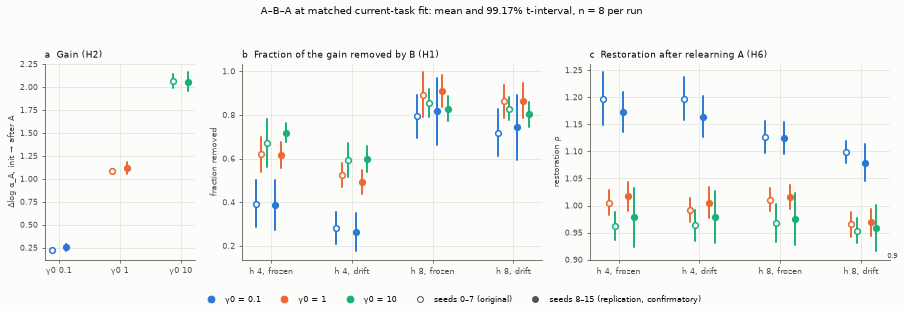

In [12]:
show(S.figF1)
fig = S.figF1(DATA, plt)
plt.show()


### F2. Channel shares (H5 configurations)

**What it shows.** How the loss B causes to A splits into utility (violet), dimension (yellow) and radius
(pink). The configurations are h 4/h 8 × frozen/drift, with one stacked bar per γ₀ and run (hatched left =
seeds 0–7, solid right = 8–15). Values are printed on segments ≥ 0.12.
- At **γ₀ 10**, utility + dimension carry about 0.92–0.95 (H5a): the rich learner forgets by
  **misaligning** its task directions and spreading, not by inflating the clouds.
- At **γ₀ 0.1** the radius share is about 0.4. The lazy learner's forgetting is partly "the clouds got
  bigger relative to their separation".
- The dashed 0.5 line is the H5b bound ("no channel carries more than half at γ₀ 0.1").

**How it is computed.** `share(r, c)` = channel c of Δlog α_A(after A → after B) / its total, per arm. The
bar height is the mean share over 8 seeds. Mean shares sum to about 1; the residual is about 0 and is not
drawn.

def figF2(data, plt):
    from matplotlib.patches import Patch
    fig, axes = plt.subplots(1, 4, figsize=(13, 4.4), sharey=True)
    w = 0.36
    for ax, (h, sf) in zip(axes, H_CFGS):
        _style(ax)
        for k, gm in enumerate(GAMMAS):
            for run, A in data.items():
                filled, off = RUN_STYLE[run]
                x = k + (w / 2 + 0.02) * (1 if filled else -1)
                bottom = 0.0
                for ch, col in CH_COL.items():
                    v = float(np.mean([share(A[s, gm, h, sf], ch) for s in seeds_of(run)]))
                    ax.bar(x, v, w, bottom=bottom, color=col if filled else "white", edgecolor=col,
                           linewidth=1.2, hatch=None if filled else "////")
                    if v >= 0.12:
                        ax.text(x, bottom + v / 2, f"{v:.2f}", ha="center", va="center", fontsize=6.5, color=INK)
                    bottom += v
        ax.axhline(0.5, color=INK2, lw=1, ls="--")
        ax.set_xticks(range(3), [

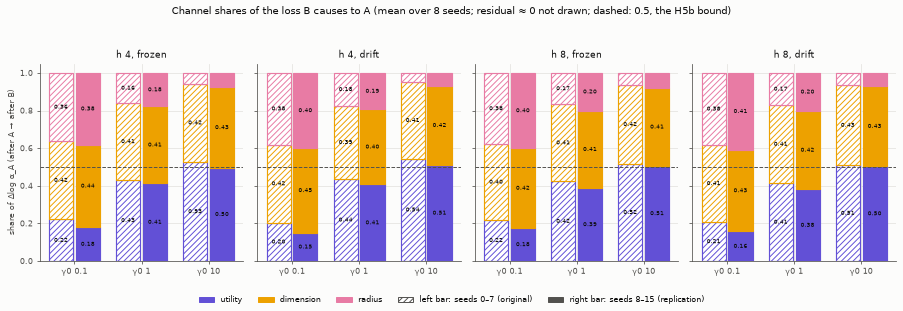

In [13]:
show(S.figF2)
fig = S.figF2(DATA, plt)
plt.show()


### F3. Accuracy vs capacity at frozen input

**What it shows.** Each marker is one seed at one boundary, at frozen input (h 0, 4, 8):
- x = log α_A (capacity);
- y = bottleneck-probe accuracy on A;
- marker shape = phase (◆ init, ● after A, ■ after B, ▲ after A again);
- colour = γ₀.

**Reading it.** Capacity and readable accuracy move together. Rich learners (green) sit top right after A
(high capacity, accuracy about 1). At h 4/h 8, after B (■) they move down and to the left along the same
cloud. The init markers of all γ₀ coincide, because every γ₀ starts from the same W(0) and init features do
not depend on γ₀ (I6).

**How it is computed.** `level(r, phase)` = log α_A at that boundary; `r["bottleneck"][phase]["acc"]` (§5c).

def figF3(data, plt):
    from matplotlib.lines import Line2D
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), sharex=True, sharey=True)
    pm = {"init": "D", "A1": "o", "B": "s", "A2": "^"}
    for ax, h in zip(axes, HS):
        _style(ax)
        for run, A in data.items():
            filled, _ = RUN_STYLE[run]
            for gm in GAMMAS:
                for ph, mk in pm.items():
                    xs = [level(A[s, gm, h, 1.0], ph) for s in seeds_of(run)]
                    ys = [A[s, gm, h, 1.0]["bottleneck"][ph]["acc"] for s in seeds_of(run)]
                    ax.scatter(xs, ys, marker=mk, s=18, color=GCOL[gm] if filled else "white",
                               edgecolors=GCOL[gm], linewidths=0.9, alpha=0.85)
        ax.set_title(f"h {h}, frozen input (s_f 1)", fontsize=9, color=INK)
        ax.set_xlabel("log α_A", fontsize=8, color=INK2)
    axes[0].set_ylabel("bottleneck-probe accuracy on A (n = 16)", fontsize=8, color=INK2)
    extra = [Line2D([], [], marker=m,

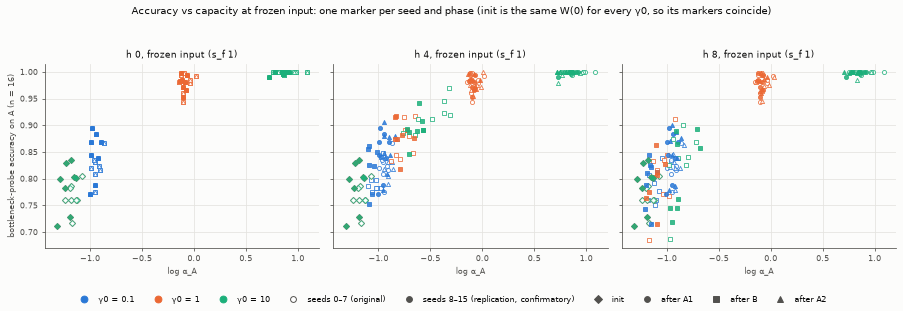

In [14]:
show(S.figF3)
fig = S.figF3(DATA, plt)
plt.show()


### F4. Protocol robustness (docs/31–32)

**What it shows.** Whether H1 depends on the stopping rule. docs/32 crossed the A-phase rule {Cr =
criterion, Fx = fixed 2300 updates} with the B-phase rule {Cr, Fx = 2400 updates}. Seeds 8–15 only.
- **(a)** The H1 contrast d = f(γ₀ 10) − f(γ₀ 0.1) in each of the four combinations, at h 4 drift (filled)
  and h 4 frozen (hollow). At drift it is positive in all four (+0.18 to +0.33).
- **(b)** The two main effects on f, per stratum:
  - E_A, over-training A: ●, the average over B's rules of f(A Fx) − f(A Cr);
  - E_B, extra B updates: ■, the average over A's rules of f(B Fx) − f(B Cr).

  Each comes with its four-category label. At γ₀ 10, over-training A lowers f (−0.08/−0.14). At γ₀ 0.1,
  extra B updates raise f (+0.06/+0.07). Both are "nonzero, possibly trivial".

**How it is computed.** `frac_removed` per arm, paired per seed. Intervals are 99.375%, and the grey band is
the SESOI ±0.10.

def figF4(cells, plt):
    from matplotlib.lines import Line2D
    S = list(SEEDS_32)

    def f(c, g, sf):
        return np.array([frac_removed(cells[c][s, g, sf]) for s in S])

    def pt(ax, x, v, col, filled, mk="o"):
        m, lo, hi = ci_at(v, T8)
        ax.plot([x, x], [lo, hi], color=col, lw=2, solid_capstyle="round", zorder=3)
        ax.scatter([x], [m], marker=mk, s=36, zorder=4, color=col if filled else "white", edgecolors=col,
                   linewidths=1.6)
        return m, lo, hi

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
    ax = axes[0]
    _style(ax)
    ax.axhspan(-0.10, 0.10, color=GRID, alpha=0.6, lw=0)
    ax.axhline(0, color=INK2, lw=1)
    for c, cell in enumerate(CELLS_32):
        for sf, off, filled in ((0.9, 0.1, True), (1.0, -0.1, False)):
            pt(ax, c + off, f(cell, 10.0, sf) - f(cell, 0.1, sf), INK, filled)
    ax.set_xticks(range(4), [f"A {c.split(',')[0]}, B {c.split(',')[1]}" for c in CELLS_32], fontsize=8)
    ax.set_ylabel(

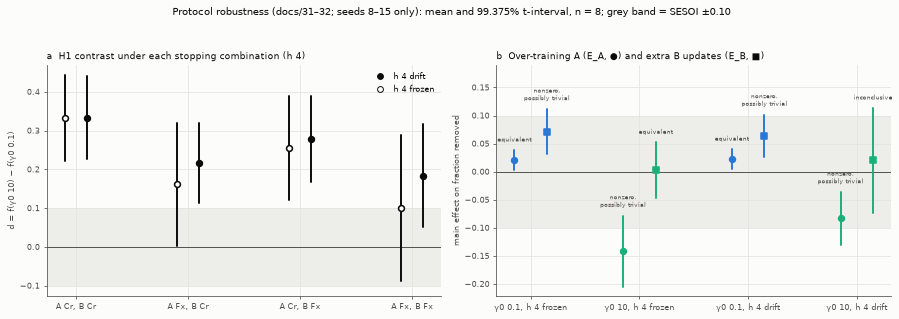

In [15]:
show(S.figF4)
fig = S.figF4(CELLS32, plt)
plt.show()


### F5. Behaviour on A at each boundary

**What it shows.** Accuracy on A's test points at each boundary, seeds 8–15, with γ₀ by colour:
- **solid** = the network's own sign accuracy (§5a; not defined at init);
- **dashed** = the bottleneck probe (§5c);
- dotted = chance 0.5.

**Reading it.**
- **Behaviour vs representation.** After B at frozen input, the network's own accuracy drops to exactly
  1 − h/16 (0.75 at h 4, 0.50 at h 8) at **every** γ₀. That is the readout now answering with y_B. The
  bottleneck probe stays much higher (about 0.8–0.9): **the features still contain A**, even when the network's
  answer does not.
- At jump, B's inputs are new, so B barely disturbs A's behaviour.
- After relearning A, both return to about 1.

**How it is computed.** Solid: `r["trajectory"][phase][-1]["A_test_acc"]`, the last record of each phase.
Dashed: `r["bottleneck"][phase]["acc"]`. Mean and 99.17% interval.

def figF5(data, plt):
    """Behaviour on A at each boundary (seeds 8–15): network accuracy (solid) and bottleneck probe (dashed)."""
    from matplotlib.lines import Line2D
    run = "seeds 8–15"
    A, seeds = data[run], seeds_of(run)
    fig, axes = plt.subplots(3, 3, figsize=(11, 9), sharex=True, sharey=True)
    for i, h in enumerate(HS):
        for j, sf in enumerate(SFS):
            ax = axes[i, j]
            _style(ax)
            ax.axhline(0.5, color=INK2, lw=1, ls=":")
            for k, gm in enumerate(GAMMAS):
                o = (k - 1) * 0.08
                net = [[A[s, gm, h, sf]["trajectory"][p][-1]["A_test_acc"] for s in seeds] for p in ("A1", "B", "A2")]
                bot = [[A[s, gm, h, sf]["bottleneck"][p]["acc"] for s in seeds] for p in PHASES]
                for xs, series, ls in ((np.arange(1, 4) + o, net, "-"), (np.arange(4) + o, bot, "--")):
                    ms = [ci(v) for v in series]
                    ax.plot(xs, [m[0] for m in ms], color=GCOL[g

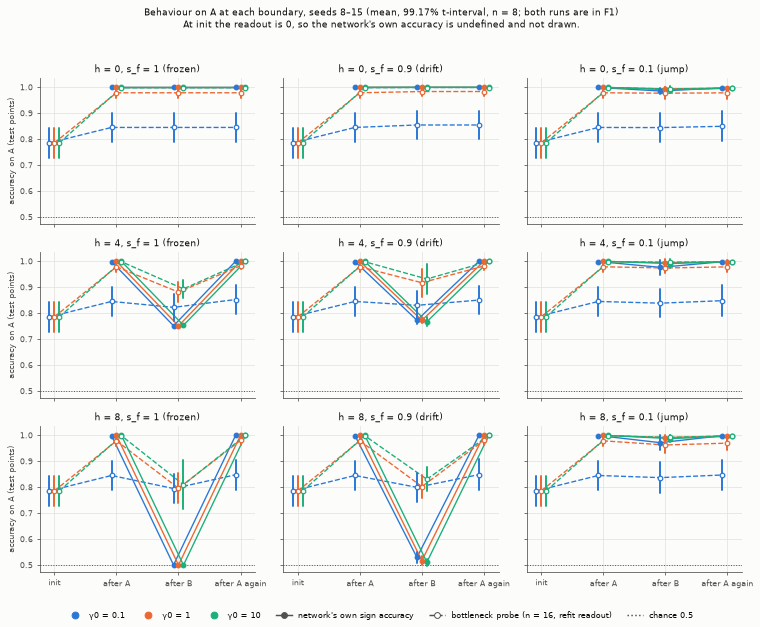

In [16]:
show(S.figF5)
fig = S.figF5(DATA, plt)
plt.show()


### F6. Forest plot of contrasts, all nine configurations

**What it shows.** One row per configuration and one column per quantity, with γ₀ by colour and both runs
(hollow/filled):
- **f** (fraction removed): rises with h; small at jump; negative (a gain) at h 0 drift;
- **ρ** (restoration): reference 1 ± 0.10, with the dashed H6 threshold 0.9;
- **FT_geo specific**: large at h 0 frozen and drift (same labels on similar inputs), about 0 at jump and at h 8;
- **FT_beh specific**: against h 8 jump, so that row is 0 by construction. Large at h 0 frozen (B needs 0
  updates). Slightly negative at h 8 frozen (H4: conflicting labels on the same inputs slow B down).

The grey bands are reference ± SESOI.

**How it is computed.** §4 and §6 quantities per arm. FT_beh specific is paired per seed and γ₀ against
h 8 jump. Mean and 99.17% interval.

def figF6(data, plt):
    """Forest plot over the 9 configurations: f, ρ, FT_geo specific, FT_beh specific (vs h 8 jump)."""
    LOG125 = math.log(1.25)
    panels = [("fraction removed f", lambda r, A, s, g: frac_removed(r), 0.0, 0.10),
              ("restoration ρ", lambda r, A, s, g: restoration(r), 1.0, 0.10),
              ("FT_geo specific (neutral baseline)", lambda r, A, s, g: r["forward"]["specific"], 0.0, 0.05),
              ("FT_beh specific (− FT_beh at h 8 jump)",
               lambda r, A, s, g: r["behaviour"]["FT_beh"] - A[s, g, 8, 0.1]["behaviour"]["FT_beh"], 0.0, LOG125)]
    fig, axes = plt.subplots(1, 4, figsize=(14, 6.4), sharey=True)
    ys = {c: len(CONFIGS9) - 1 - i for i, c in enumerate(CONFIGS9)}
    for ax, (lab, fn, ref, ses) in zip(axes, panels):
        _style(ax)
        ax.axvspan(ref - ses, ref + ses, color=GRID, alpha=0.6, lw=0)
        ax.axvline(ref, color=INK2, lw=1)
        if lab.startswith("restoration"):
            ax.axvline(0.9, color=INK2,

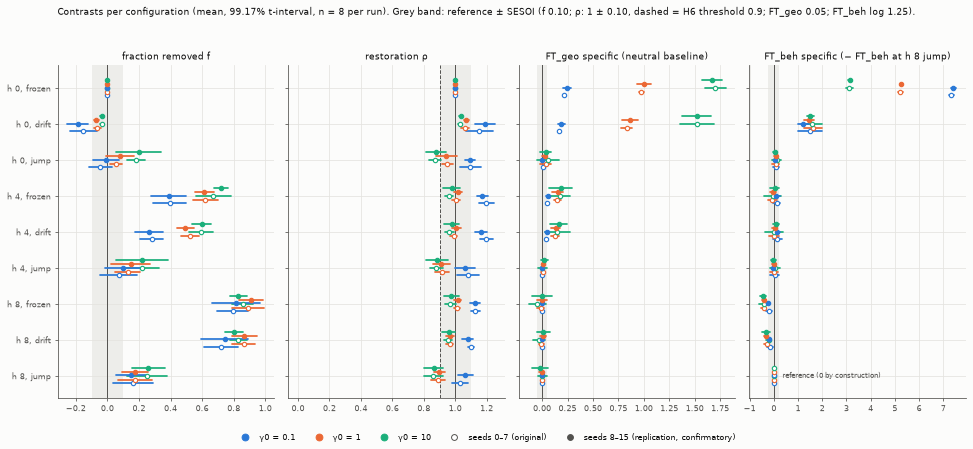

In [17]:
show(S.figF6)
fig = S.figF6(DATA, plt)
plt.show()


### F7. Channel shares, all nine configurations

**What it shows.** F2 extended to all nine configurations, jump included.
- **Grey "not read" cells.** A share is only meaningful when the total it divides is resolved, so a cell is
  greyed when Δ_total(after A → after B) is not resolved (interval includes 0, or |mean| < 2 floors). This is
  the case at h 0 frozen (B does nothing), at most of jump, and in a few drift cells.
- **Negative shares.** A share can be negative when one channel moves against the total. Such segments are
  drawn below 0, for example radius −0.28 at h 0 jump, γ₀ 1, seeds 0–7.
- **h 0 drift.** Δ_total > 0 there (B *adds* capacity, H3), so those shares are of a **gain**.

**How it is computed.** As F2, plus `_dtotal_resolved` (below), which applies the docs/28 rule with the
run's floors.

def _dtotal_resolved(A, run, g, h, sf) -> bool:
    """docs/28 §3: the H5 denominator Δ_total(A1 → B) is resolved (99.17% interval excludes 0, ≥ 2 floors)."""
    t = ci([A[s, g, h, sf]["backward"]["A1_to_B"]["total"] for s in seeds_of(run)])
    return res_sign(t, FLOORS_928[run][g]) != 0

def figF7(data, plt):
    """Channel shares of Δlog α_A(A1 → B) in all 9 configurations; cells whose denominator is unresolved
    (docs/28 §3) are grey and labelled 'not read'."""
    from matplotlib.patches import Patch
    fig, axes = plt.subplots(3, 3, figsize=(13, 10), sharey=True)
    w = 0.36
    for i, h in enumerate(HS):
        for j, sf in enumerate(SFS):
            ax = axes[i, j]
            _style(ax)
            for k, gm in enumerate(GAMMAS):
                for run, A in data.items():
                    filled, _ = RUN_STYLE[run]
                    x = k + (w / 2 + 0.02) * (1 if filled else -1)
                    if not _dtotal_resolved(A, run, gm, h, sf):
                      

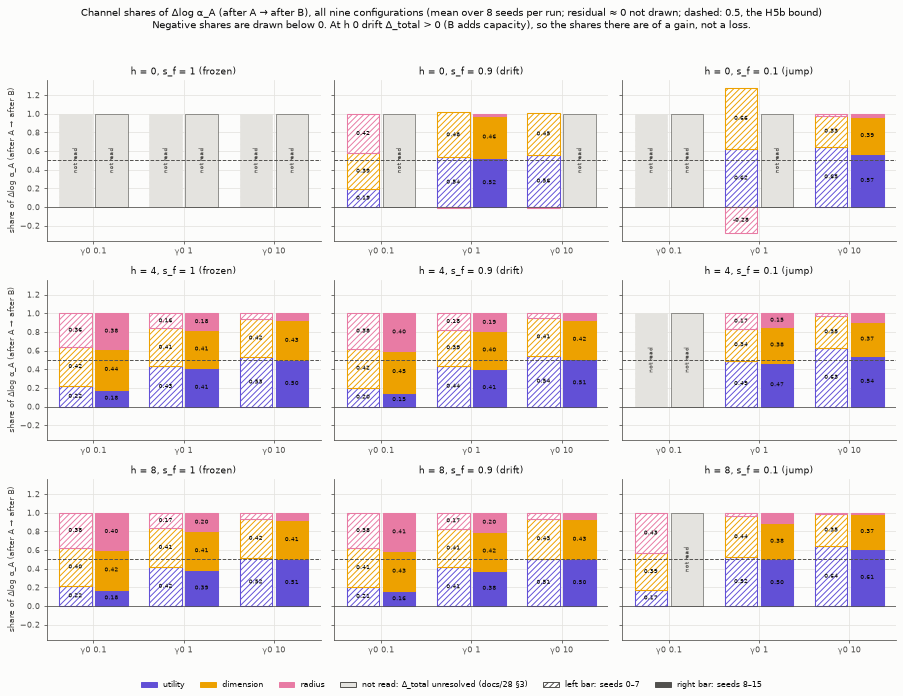

In [18]:
show(S._dtotal_resolved)
show(S.figF7)
fig = S.figF7(DATA, plt)
plt.show()


**Numbers behind F5's main point** (seeds 8–15, mean over seeds; after B):


In [19]:
rows = []
for h in (4, 8):
    for sf in (1.0, 0.9):
        for g in cfg.gammas:
            rs = [A8[s, g, h, sf] for s in range(8, 16)]
            rows.append([h, S.SF_NAME[sf], g, f"{np.mean([x['trajectory']['B'][-1]['A_test_acc'] for x in rs]):.3f}",
                         f"{1 - h / 16:.3f}", f"{np.mean([x['bottleneck']['B']['acc'] for x in rs]):.3f}"])
table(["h", "input", "γ0", "network accuracy on A after B", "1 − h/16", "bottleneck accuracy after B"], rows)


| h | input | γ0 | network accuracy on A after B | 1 − h/16 | bottleneck accuracy after B |
|---|---|---|---|---|---|
| 4 | frozen | 0.1 | 0.751 | 0.750 | 0.823 |
| 4 | frozen | 1.0 | 0.751 | 0.750 | 0.881 |
| 4 | frozen | 10.0 | 0.753 | 0.750 | 0.894 |
| 4 | drift | 0.1 | 0.773 | 0.750 | 0.830 |
| 4 | drift | 1.0 | 0.772 | 0.750 | 0.917 |
| 4 | drift | 10.0 | 0.767 | 0.750 | 0.932 |
| 8 | frozen | 0.1 | 0.501 | 0.500 | 0.795 |
| 8 | frozen | 1.0 | 0.500 | 0.500 | 0.796 |
| 8 | frozen | 10.0 | 0.500 | 0.500 | 0.810 |
| 8 | drift | 0.1 | 0.530 | 0.500 | 0.800 |
| 8 | drift | 1.0 | 0.517 | 0.500 | 0.802 |
| 8 | drift | 10.0 | 0.511 | 0.500 | 0.831 |

## 9. Glossary

| term | meaning |
|---|---|
| A, B, A2 | the three training phases: learn A, then B, then A again |
| h | Hamming distance between y_A and y_B (labels flipped, of 16) |
| s_r | label relation 1 − 2h/16: +1 same, 0 uncorrelated, −1 all flipped |
| s_f | input-centre relation of B to A: 1 frozen, 0.9 drift, 0.1 jump |
| ρ_in | realised mean cosine of matched A/B centres |
| γ₀ | μP richness: 0.1 lazy (features barely move), 10 rich (features align to the task) |
| matched-loss stopping | every phase trains until loss ≤ 0.05; the learner sets its own number of updates |
| exposure | number of updates in a phase |
| α, log α | GLUE capacity of A's 16 hidden-layer manifolds under y_A (linear separability with margin) |
| utility / radius / dimension | the exact three-way split of Δlog α (Ψ_eff, R_eff, D_eff) |
| gain G | log α after A − log α at init |
| fraction removed f | share of the gain B removed |
| restoration ρ | share of the gain present after relearning A (1 = full) |
| refit readout | fresh linear readout trained on the frozen 300-unit hidden layer; saturates (~0.995 even at init) |
| bottleneck probe | fresh readout on a fixed random 16-dimensional projection of the hidden layer; calibrated to ~0.75 at init, so it can move both ways |
| FT_geo specific | capacity change for y_B on B's manifolds caused by learning A, minus the same for neutral labels |
| FT_beh | log of how many fewer updates B needs after A than from scratch |
| floor | SD of log α across GLUE estimator keys: measurement noise |
| resolved | interval excludes 0 and |mean| ≥ 2 floors (docs/28) |
| SESOI | smallest effect size of interest (docs/29 S0) |
